# Creating a map with topographic hillshading

In [3]:
using Pkg
Pkg.activate("../")
Pkg.instantiate()
using Glob
using CairoMakie
using GeoMakie
using Colors
using Rasters
using ArchGDAL
using Statistics
using LinearAlgebra
using JupyterFormatter
enable_autoformat()

  Activating project at `~/Projects/maps-with-makie`
┌ Warning: The active manifest file has dependencies that were resolved with a different julia version (1.13.2). Unexpected behavior may occur.
└ @ ~/Projects/maps-with-makie/Manifest.toml:0
Precompiling packages...
              ✗ Zstd_jll
   1703.8 ms  ✓ libsixel_jll
   8976.0 ms  ✓ StaticArrayInterface → StaticArrayInterfaceStaticArraysExt
   9310.5 ms  ✓ RegionTrees
  12013.6 ms  ✓ ArnoldiMethod
  10657.9 ms  ✓ Rasters → RastersCoordinateTransformationsExt
  12557.9 ms  ✓ Rotations
  13062.7 ms  ✓ FastInterpolations → FastInterpolationsRecipesBaseExt
              ✗ CodecZstd
              ✗ ChunkCodecLibZstd
              ✗ Blosc_jll
              ✗ libzip_jll
   6163.7 ms  ✓ LoopVectorization → SpecialFunctionsExt
  15747.2 ms  ✓ NearestNeighbors
              ✗ LibPQ_jll
              ✗ Libtiff_jll
              ✗ Arrow_jll
   9988.2 ms  ✓ Sixel
  12330.1 ms  ✓ JpegTurbo
  27107.2 ms  ✓ ImageAxes
   1151.5 ms  ✓ Rotations → Ro

LoadError: InterruptException:

== at ./promotion.jl:637 [inlined]
_useref_getindex at ./../usr/share/julia/Compiler/src/ssair/ir.jl:545
jfptr__useref_getindex_6457.1 at /home/ctroupin/.julia/juliaup/julia-1.12.7+0.x64.linux.gnu/lib/julia/sys.so (unknown line)
tojlinvoke84994.1 at /home/ctroupin/.julia/juliaup/julia-1.12.7+0.x64.linux.gnu/lib/julia/sys.so (unknown line)
j__useref_getindex_80033.1 at /home/ctroupin/.julia/juliaup/julia-1.12.7+0.x64.linux.gnu/lib/julia/sys.so (unknown line)

[51644] signal 2: Interrupt
in expression starting at /home/ctroupin/.julia/packages/CairoMakie/M4iiC/src/CairoMakie.jl:3
epoll_pwait at /lib/x86_64-linux-gnu/libc.so.6 (unknown line)
getindex at ./../usr/share/julia/Compiler/src/ssair/ir.jl:578 [inlined]
ssa_substitute_op! at ./../usr/share/julia/Compiler/src/ssair/inlining.jl:1836
ir_inline_item! at ./../usr/share/julia/Compiler/src/ssair/inlining.jl:417
batch_inline! at ./../usr/share/julia/Compiler/src/ssair/inlining.jl:663
ssa_inlining_pass! at ./../usr/share/julia/Compiler/sr

poptask at ./task.jl:1216
wait at ./task.jl:1228
#wait#406 at ./condition.jl:141
wait at ./condition.jl:136 [inlined]
_trywait at ./asyncevent.jl:185
#656 at ./asyncevent.jl:359
jfptr_YY.656_17795.1 at /home/ctroupin/.julia/juliaup/julia-1.12.7+0.x64.linux.gnu/lib/julia/sys.so (unknown line)
jl_apply at /cache/build/builder-amdci5-2/julialang/julia-ci/src/julia.h:2394 [inlined]
start_task at /cache/build/builder-amdci5-2/julialang/julia-ci/src/task.c:1253
unknown function (ip: (nil)) at (unknown file)
Allocations: 1016525 (Pool: 1016521; Big: 4); GC: 2


## Data
We use a geoTIFF file containg the elevation and the coordinates (in decimal degrees).     
In this case (Mallorca), we downloaded the digital terrain model (DTM) from the Spanish [Instituto Geográfico Nacional](https://centrodedescargas.cnig.es/). 

The coordinates and the DTM are read using [`Raster`](https://rafaqz.github.io/Rasters.jl/stable/).

In [37]:
figdir = "./"
datafile = "/media/ctroupin/My Passport/data/DTM/Mallorca-25/Mallorca_proj.tif"
raster_mallorca = Raster(datafile)
lon = Array(lookup(raster_mallorca, X));
lat = Array(lookup(raster_mallorca, Y));
mallorcaDTM = Float64.(coalesce.(Array(raster_mallorca.data), NaN));

### Simple plot

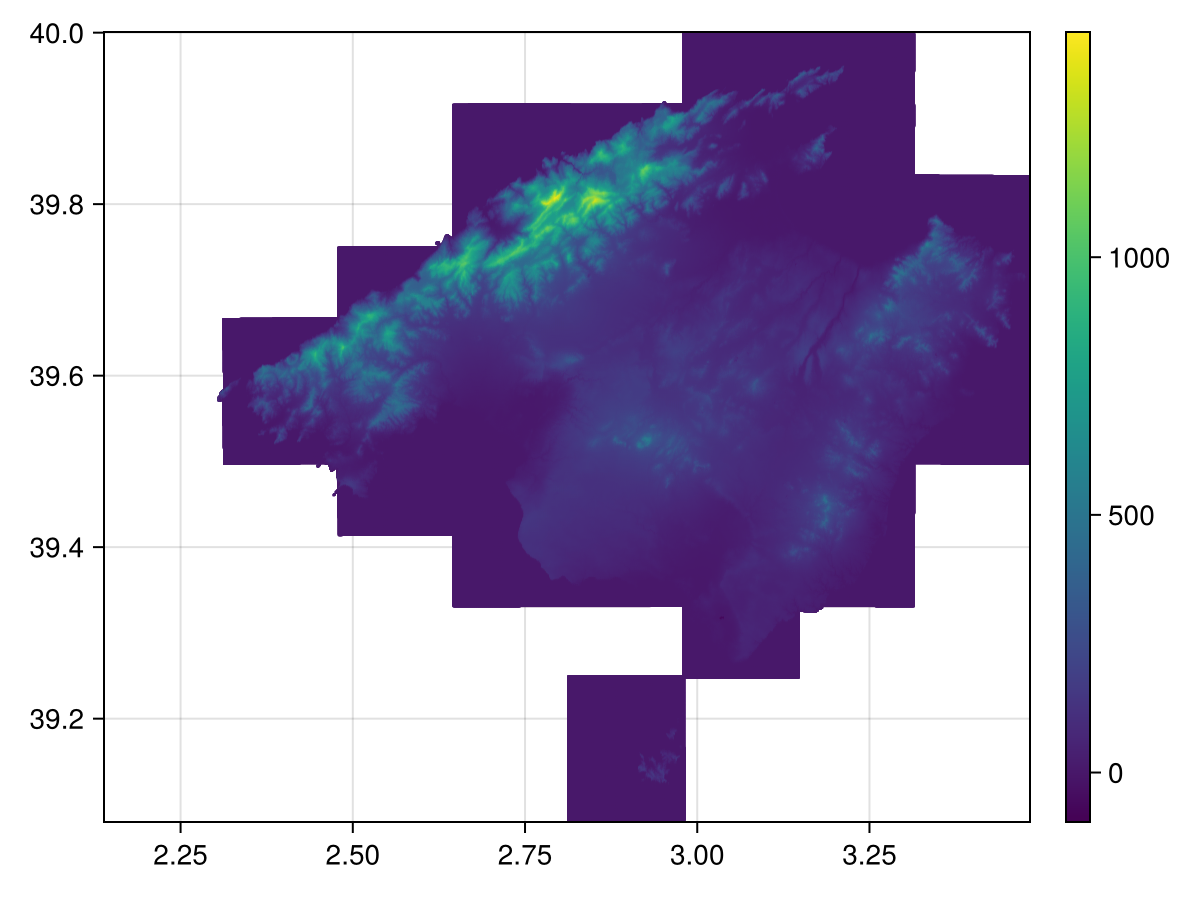

CairoMakie.Screen{IMAGE}


In [4]:
fig = Figure()
ax = Axis(fig[1, 1])
hm = heatmap!(ax, lon, lat, mallorcaDTM)
Colorbar(fig[1, 2], hm)
display(fig)

## Compute the hillshading

In [27]:
function hillshade(
    lon::Vector{Float64},
    lat::Vector{Float64},
    DTM::Matrix{Float64};
    azimuth::Int64 = 315,
    altitude::Int64 = 45,
    exaggeration::Float64 = 1.0,
)

    xmin = lon[1]
    xmax = lon[end]
    ymin = lat[1]
    ymax = lat[end]

    # Mask negative values
    DTM[DTM.<=0.0] .= NaN

    # Compute cell size in meters
    nx, ny = size(DTM)

    dlon, dlat = (xmax - xmin) / nx, (ymax - ymin) / ny
    geographic = true                                    # false if the DTM is in a projected CRS (metres)
    dx = geographic ? dlon * 111_320 * cosd((ymin + ymax) / 2) : dlon
    dy = geographic ? dlat * 110_574 : dlat

    az, alt = deg2rad(azimuth), deg2rad(altitude)
    L = (sin(az) * cos(alt), cos(az) * cos(alt), sin(alt))   # x = east, y = north
    zz(i, j) = z[clamp(i, 1, nx), clamp(j, 1, ny)] * exaggeration
    # Allocate matrix
    shade = similar(DTM)

    # Loop over all elements
    for j = 1:ny, i = 1:nx


        # Horn's method
        dzdx =
            (
                (zz(i + 1, j + 1) + 2zz(i + 1, j) + zz(i + 1, j - 1)) -
                (zz(i - 1, j + 1) + 2zz(i - 1, j) + zz(i - 1, j - 1))
            ) / (8dx)
        dzdy =
            (
                (zz(i - 1, j + 1) + 2zz(i, j + 1) + zz(i + 1, j + 1)) -
                (zz(i - 1, j - 1) + 2zz(i, j - 1) + zz(i + 1, j - 1))
            ) / (8dy)
        n = sqrt(dzdx^2 + dzdy^2 + 1)
        shade[i, j] = (-dzdx * L[1] - dzdy * L[2] + L[3]) / n
    end
    return shade
end

hillshade (generic function with 2 methods)

In [28]:
shade1 = hillshade(lon, lat, mallorcaDTM; azimuth = 315, altitude = 45, exaggeration = 20.0);

### Simple plot

In [ ]:
fig = Figure(size = (800, 600))
ax1 = Axis(fig[1, 1])
hm1 = heatmap!(ax1, lon, lat, shade1, colormap = Reverse(:Greys))
hidedecorations!(ax1)
hidespines!(ax1)
save(joinpath(figdir, "mallorcaDTM1.png"), fig)
# display(fig)

## Compute elevation with shading

In [41]:
mallorcaDTM[mallorcaDTM.<=0.0] .= NaN

fig = Figure(size = (800, 600))
ax1 = Axis(fig[1, 1])
hm1 = heatmap!(ax1, lon, lat, mallorcaDTM, colormap = Reverse(:speed))
hm2 = heatmap!(ax1, lon, lat, shade1, colormap = Reverse(:Greys), alpha = 0.7)
hidedecorations!(ax1)
hidespines!(ax1)
save(joinpath(figdir, "mallorcaDTM2.png"), fig)

In [45]:
lo, hi = quantile(filter(!isnan, vec(shade1)), (0.02, 0.98))   # using Statistics

(-0.592554050357582, 0.9728063475287947)

In [76]:
mallorcaDTM[mallorcaDTM.<=0.0] .= NaN

cptfilelist = glob("*.cpt", "./")
for cptfile in cptfilelist
    cpt = read_cpt(cptfile)
    @info("Working on $cptfile")

    fig = Figure()
    ga = GeoAxis(fig[1, 1]; source = "+proj=longlat +datum=WGS84", dest = "+proj=merc")

    # 1. Elevation (bottom layer)
    hm = heatmap!(
        ga,
        lon,
        lat,
        mallorcaDTM;
        colormap = cpt.colors,
        colorrange = (0.0, 1300.0),
        nan_color = :transparent,
    )

    # 2. Hillshade (top layer): shadows are black with alpha, highlights are white with alpha
    shade_cmap = [RGBA(0, 0, 0, 0.75), RGBA(0, 0, 0, 0.0), RGBA(1, 1, 1, 0.35)]
    heatmap!(
        ga,
        lon,
        lat,
        shade1;
        colormap = shade_cmap,
        colorrange = (lo, hi),
        nan_color = :transparent,
    )
    hidedecorations!(ga)
    # Colorbar(fig[1, 2], hm; label = "Elevation (m)")
    save(joinpath(figdir, "mallorcaDTM_$(split(basename(cptfile), ".")[1]).png"), fig)
    # display(fig)
end

[ Info: Working on ./europe_2.cpt
[ Info: Working on ./europe_3.cpt
[ Info: Working on ./europe_4.cpt
[ Info: Working on ./europe_5.cpt
[ Info: Working on ./europe_6.cpt
[ Info: Working on ./europe_7.cpt
[ Info: Working on ./europe_8.cpt
[ Info: Working on ./italy.cpt
[ Info: Working on ./portugal.cpt
[ Info: Working on ./spain.cpt


In [ ]:
using Colors

"""
    read_cpt(path; n = 256)

Read a GMT/cpt-city .cpt file (RGB colour model, numeric r/g/b entries).
Returns a named tuple with `colors` (n-element colormap), `range` (zmin, zmax),
and `under`/`over`/`nan` colours from the B/F/N lines (or `nothing`).
"""
function read_cpt(path; n = 256)
    segs = Tuple{Float64,RGB{Float64},Float64,RGB{Float64}}[]
    special = Dict{Char,RGB{Float64}}()
    rgb(r, g, b) =
        RGB(parse(Float64, r) / 255, parse(Float64, g) / 255, parse(Float64, b) / 255)

    for line in eachline(path)
        s = strip(line)
        (isempty(s) || startswith(s, '#')) && continue
        t = split(replace(s, '/' => ' ', '\t' => ' '))
        if t[1] in ("B", "F", "N")                       # background / foreground / NaN colour
            special[t[1][1]] = rgb(t[2], t[3], t[4])
        else                                             # z0 r g b z1 r g b
            push!(
                segs,
                (
                    parse(Float64, t[1]),
                    rgb(t[2], t[3], t[4]),
                    parse(Float64, t[5]),
                    rgb(t[6], t[7], t[8]),
                ),
            )
        end
    end

    zmin, zmax = segs[1][1], segs[end][3]

    function color_at(z)
        for (z0, c0, z1, c1) in segs
            if z <= z1
                t = z1 == z0 ? 0.0 : clamp((z - z0) / (z1 - z0), 0, 1)
                return RGB(
                    c0.r + t * (c1.r - c0.r),
                    c0.g + t * (c1.g - c0.g),
                    c0.b + t * (c1.b - c0.b),
                )
            end
        end
        return segs[end][4]
    end

    colors = [color_at(z) for z in range(zmin, zmax, length = n)]
    return (;
        colors,
        range = (zmin, zmax),
        under = get(special, 'B', nothing),
        over = get(special, 'F', nothing),
        nan = get(special, 'N', nothing),
    )
end

